# Чекпоинт 2: разведочный анализ данных Reels Router

Research-трек, проект 205. Сводка подготовлена 3 ноября 2026; дедлайн — 7 ноября, 23:59. [Требования организаторов](https://docs.google.com/document/d/1Izow1n6RTf-iP6MEXE3zVH9i5-gBoFUr4uJvCLKhh1U/edit): анализ данных и развёрнутые выводы в EDA.ipynb, отдельно PDF о практической ценности.

Это итоговая сводка уже выполненных исследований. Ячейки ниже действительно выполняются, но читают сохранённые JSON и показывают избранные результаты. Исходные корпуса и прежние ноутбуки повторно не запускаются. Для каждого результата указаны источник и единица наблюдения; количества из разных источников не складываются.

[Практическая ценность, PDF](docs/practical-value.pdf) · [Редактируемый текст](docs/practical-value.md). Порядок: источники → качество данных → географический перекос → дополнительные корпуса → аугментации → решения для проекта.



In [1]:
import json
from pathlib import Path
from html import escape
from IPython.display import display, HTML
import matplotlib.pyplot as plt

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p/"docs/checkpoint-2-evidence.json").is_file())

def read(path):
    return json.loads((ROOT/path).read_text(encoding="utf-8"))

def table(rows):
    keys = list(rows[0]) if rows else []
    display(HTML("<table><tr>" + "".join(f"<th>{escape(str(k))}</th>" for k in keys)
                 + "</tr>" + "".join("<tr>" + "".join(f"<td>{escape(str(r.get(k,'')))}</td>"
                 for k in keys) + "</tr>" for r in rows) + "</table>"))

evidence = read("docs/checkpoint-2-evidence.json")
tripworld = read("research/notebooks/tripworld/results/metrics.json")
augmentations = read("research/results/reels_augmentations/summary.json")
print("Основа обзора:", evidence["baseline_commit"])
print("Дата сводки:", evidence["compiled_on"])
print("TripWorld revision:", tripworld["revision"])
print("Сводки прочитаны; загрузки данных и вызовы моделей не выполняются.")

Основа обзора: dd9b7ba
Дата сводки: 2026-11-03
TripWorld revision: 421bc1dc63068bb398055b1ce987265fe22415db
Сводки прочитаны; загрузки данных и вызовы моделей не выполняются.


## 1. Источники и единицы анализа

Объектом исследования являются разные этапы задачи: словари мест, разметка упоминаний, визуальные признаки и последовательности посещений. Каталог POI не равен корпусу видео, а check-in не равен посещению в оптимальном маршруте.

Подробные EDA с исходными кодом, таблицами, визуализациями и выводами:
- [Google Landmarks Places](https://github.com/kaNEGY/reels-router/blob/dd9b7ba0253d744fd0e43da17f9410b64e9a8197/research/notebooks/google_landmarks_places_eda.ipynb).
- [Overture, OSM, Wikidata и дополнительные источники](https://github.com/kaNEGY/reels-router/blob/dd9b7ba0253d744fd0e43da17f9410b64e9a8197/research/notebooks/simple_eda.ipynb).
- [VIR-Bench](https://github.com/kaNEGY/reels-router/blob/dd9b7ba0253d744fd0e43da17f9410b64e9a8197/research/notebooks/virbench_eda.ipynb).
- [TripWorld: исследование](https://github.com/kaNEGY/reels-router/blob/dd9b7ba0253d744fd0e43da17f9410b64e9a8197/research/notebooks/tripworld/README.md), [код](research/notebooks/tripworld/eda.py), [метрики](research/notebooks/tripworld/results/metrics.json).
- [Аугментации Reels](research/notebooks/reels_augmentations.ipynb).

Числа по первым трём источникам перенесены из сохранённых outputs в docs/checkpoint-2-evidence.json с указателями на ячейки. Метрики TripWorld и аугментаций читаются из опубликованных машинных результатов. Исходные локальные выгрузки Overture/OSM и часть вспомогательных файлов не включены в Git: их повторное воспроизведение требует восстановления данных; сохранённые результаты доступны для чтения.

In [2]:
table([
    {"источник": "Google Landmarks Places", "объём": evidence["google_landmarks"]["records"],
     "единица": "запись POI", "роль": "каталог координат и названий"},
    {"источник": "Overture: центр Петербурга", "объём": evidence["overture_spb"]["records"],
     "единица": "запись POI в выбранном bbox", "роль": "поиск кандидатов"},
    {"источник": "VIR-Bench test", "объём": evidence["virbench"]["test_videos"],
     "единица": "YouTube-видео с графом разметки", "роль": "структура мест/упоминаний"},
    {"источник": "TripWorld POI", "объём": tripworld["tables"]["pois"]["rows"],
     "единица": "объект каталога", "роль": "каталог и связи с посещениями"},
    {"источник": "TripWorld travel", "объём": tripworld["tables"]["travel"]["rows"],
     "единица": "пользователь - домашний регион - регион назначения", "роль": "рекомендации POI"},
    {"источник": "Пилот Reels", "объём": augmentations["reels_received"],
     "единица": "пользовательская ссылка", "роль": "свойства медиа и аугментации"},
])

источник,объём,единица,роль
Google Landmarks Places,35070,запись POI,каталог координат и названий
Overture: центр Петербурга,14784,запись POI в выбранном bbox,поиск кандидатов
VIR-Bench test,200,YouTube-видео с графом разметки,структура мест/упоминаний
TripWorld POI,687173,объект каталога,каталог и связи с посещениями
TripWorld travel,518567,пользователь - домашний регион - регион назначения,рекомендации POI
Пилот Reels,8,пользовательская ссылка,свойства медиа и аугментации


## 2. Пропуски, неоднозначность и правила обработки

Проценты считаются внутри каждого источника и поля, с собственным знаменателем. Пустые строки и пустые списки учтены в исходных исследованиях; это шире проверки isna(). Пропуск города не равен отсутствию координат; отсутствие альтернативных имён не доказывает, что объект не имеет других названий.

Нельзя подставлять средние координаты или выдуманное название. Неизвестные значения сохраняем с флагом; запись без имени временно исключаем из поиска по имени, но можем оставить для других задач. Алиасы дополняем из проверенных источников, сохраняя ID и происхождение.

источник,поле,пропусков,знаменатель,"доля, %"
Google Landmarks,название,7657,35070,21.83
Google Landmarks,город,3329,35070,9.49
Google Landmarks,регион,4877,35070,13.91
Overture SPb,алиасы,14661,14784,99.17
Overture SPb,категория,331,14784,2.24
Overture SPb,статус работы,14784,14784,100.0
VIR-Bench test,координаты,89,3594,2.48
VIR-Bench test,категория,296,3594,8.24


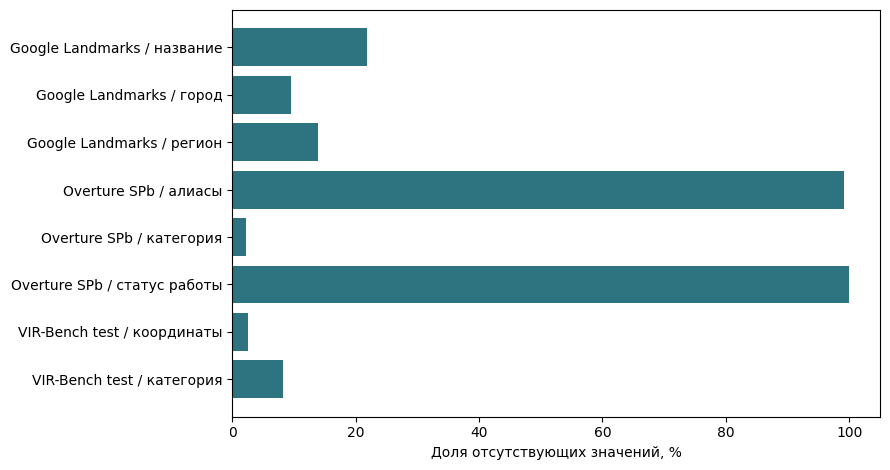

In [3]:
g = evidence["google_landmarks"]
o = evidence["overture_spb"]
v = evidence["virbench"]
quality_rows = []
for source, field, missing, total in [
    ("Google Landmarks", "название", g["missing_name"], g["records"]),
    ("Google Landmarks", "город", g["missing_city"], g["records"]),
    ("Google Landmarks", "регион", g["missing_state"], g["records"]),
    ("Overture SPb", "алиасы", o["missing_aliases"], o["records"]),
    ("Overture SPb", "категория", o["missing_category"], o["records"]),
    ("Overture SPb", "статус работы", o["missing_operating_status"], o["records"]),
    ("VIR-Bench test", "координаты", v["test_poi"]-v["test_coordinates"], v["test_poi"]),
    ("VIR-Bench test", "категория", v["test_missing_category"], v["test_poi"]),
]:
    assert 0 <= missing <= total
    quality_rows.append({"источник": source, "поле": field, "пропусков": missing,
                         "знаменатель": total, "доля, %": round(100*missing/total, 2)})
table(quality_rows)
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.barh([r["источник"]+" / "+r["поле"] for r in quality_rows],
        [r["доля, %"] for r in quality_rows], color="#2d7480")
ax.set_xlabel("Доля отсутствующих значений, %")
ax.set_xlim(0, 105)
ax.invert_yaxis()
fig.tight_layout()
plt.show()

### Ошибки, выбросы и идентификаторы

Все 35 070 координат Google Landmarks лежат в допустимом диапазоне; это не проверка фактической точности на карте. Все 35 070 category_name уникальны и похожи на названия объектов: использовать их как готовые тематические классы нельзя.

В Overture 847 повторяющихся строк имён: неоднозначность имени не означает дубль объекта. В VIR-Bench повторные Places ID внутри видео могут отражать повторное посещение; пять ID встречаются между test и validation. При собственной оценке нужны группировки по авторам, поездкам и исходным роликам.

Интервалы POI VIR-Bench test варьируются от 0.4 до 857.3 с (медиана 27.2 с); длинный фрагмент нельзя автоматически удалять как ошибку. В TripWorld встречаются сегменты длиннее суток: trail_id не является готовым однодневным маршрутом. Длительность упоминания в видео, посещения и дороги различаются.

In [4]:
quality = tripworld["poi_quality"]
table([
    {"проверка TripWorld": "нет координат", "количество": quality["missing_coordinates"]},
    {"проверка TripWorld": "координаты вне диапазона", "количество": quality["invalid_coordinates"]},
    {"проверка TripWorld": "координаты (0,0)", "количество": quality["zero_coordinates"]},
    {"проверка TripWorld": "нет ни FSQ, ни Google имени", "количество": quality["missing_fsq_and_google_names"]},
    {"проверка TripWorld": "benchmark_name похож на hex-ID", "количество": quality["benchmark_name_is_hex_id"]},
    {"проверка TripWorld": "есть дата закрытия", "количество": quality["has_closed_date"]},
    {"проверка TripWorld": "дата обновления позже даты исследования", "количество": quality["refreshed_after_run_date"]},
    {"проверка TripWorld": "неизвестный регион после join", "количество": tripworld["joins"]["pois_unknown_region"]},
])
print("Доля benchmark_name с форматом ID:",
      round(100*quality["benchmark_name_is_hex_id"]/quality["rows"], 2), "%")
print("Решение: для поиска использовать fsq_name / google_name; не считать benchmark_name текстовым именем.")

проверка TripWorld,количество
нет координат,8
координаты вне диапазона,0
"координаты (0,0)",1
"нет ни FSQ, ни Google имени",3
benchmark_name похож на hex-ID,605581
есть дата закрытия,33877
дата обновления позже даты исследования,1
неизвестный регион после join,13755


Доля benchmark_name с форматом ID: 88.13 %
Решение: для поиска использовать fsq_name / google_name; не считать benchmark_name текстовым именем.


## 3. Географический перекос и структура данных

Распределение каталога не равно распределению туристов или Reels. В TripWorld преобладание нескольких стран может смещать будущий поиск и рекомендации. Число уникальных строк названий регионов в VIR-Bench также не равно числу реальных административных единиц: возможны варианты написания.

Связь имён с географией принципиальна: поиск по одному имени путал музей с гостиницей или баром в исследовании Overture/OSM. Поэтому альтернативные названия, категория и регион нужны совместно. Выборки Overture и OSM охватывают разные территории; их объёмы нельзя напрямую трактовать как качество покрытия.

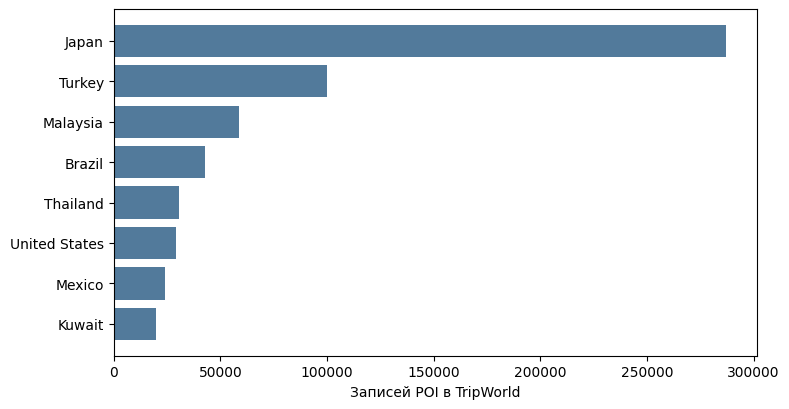

Япония + Турция + Малайзия: 446185 POI; 64.93 % каталога


диагностика,значение
целей в тесте,142026
"Hit@1 популярности внутри известного региона, %",7.34
"Hit@5 популярности внутри известного региона, %",19.48
тестовых пользователей,26928


Это сохранённый baseline TripWorld из eda.py, а не повторный запуск.
Цель — последний POI сегмента с известным регионом; история тестового сегмента не используется.
Метрика не оценивает распознавание места из ролика или удобство маршрута.


In [5]:
countries = tripworld["countries"]
top = countries[:8]
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh([r["country_name"] or "(неизвестно)" for r in top],
        [r["pois"] for r in top], color="#527a9b")
ax.set_xlabel("Записей POI в TripWorld")
ax.invert_yaxis()
fig.tight_layout()
plt.show()
top3 = sum(r["pois"] for r in countries if r["country_name"] in ["Japan", "Turkey", "Malaysia"])
print("Япония + Турция + Малайзия:", top3, "POI;",
      round(100*top3/tripworld["tables"]["pois"]["rows"], 2), "% каталога")
base = tripworld["popularity_baseline"]
table([
    {"диагностика": "целей в тесте", "значение": base["test_segments"]},
    {"диагностика": "Hit@1 популярности внутри известного региона, %", "значение": round(100*base["hits_at_1"]/base["test_segments"], 2)},
    {"диагностика": "Hit@5 популярности внутри известного региона, %", "значение": round(100*base["hits_at_5"]/base["test_segments"], 2)},
    {"диагностика": "тестовых пользователей", "значение": base["test_users"]},
])
print("Это сохранённый baseline TripWorld из eda.py, а не повторный запуск.")
print("Цель — последний POI сегмента с известным регионом; история тестового сегмента не используется.")
print("Метрика не оценивает распознавание места из ролика или удобство маршрута.")

## 4. Дополнительные источники и ограничения разметки

Числа ниже взяты из сохранённых результатов simple_eda.ipynb, раздел «Остальные источники». Материалы различаются по языкам, домену и доступным модальностям; их нельзя объединять в одну обучающую выборку без отдельной схемы и проверки лицензий.

Samuel & Audrey — англоязычные туристические транскрипты одного канала; единицей разбиения должно быть исходное видео. MTD-GEM — статьи на английском и индонезийском, в привязках сущностей обнаружены несоответствия: перед обучением нужны исправления. В CityGuessr исследованы метаданные; медиаархивы не анализировались. Audiala полезен как каталог, но наличие названия в справочнике ещё не даёт эталонного соответствия упоминанию.

In [6]:
x = evidence["other"]
table([
    {"источник": "Audiala", "объём": x["audiala_records"], "единица": "запись POI",
     "применение": "каталог и варианты названий"},
    {"источник": "Samuel & Audrey", "объём": x["samuel_audrey_videos"], "единица": "запись видео",
     "применение": "тексты туристического домена; нужна разметка мест"},
    {"источник": "Samuel & Audrey", "объём": x["samuel_audrey_utterances"], "единица": "реплика",
     "применение": "короткие текстовые окна; split по видео"},
    {"источник": "MTD-GEM", "объём": x["mtd_gem_mentions"], "единица": "размеченное упоминание",
     "применение": "извлечение сущностей после проверки привязок"},
    {"источник": "MTD-GEM FAC_NAME", "объём": x["mtd_gem_fac"], "единица": "упоминание объекта",
     "применение": "подмножество, а не дополнительный независимый корпус"},
    {"источник": "CityGuessr", "объём": x["cityguessr_metadata"], "единица": "строка метаданных",
     "применение": "возможный отдельный опыт визуальной локализации"},
])

источник,объём,единица,применение
Audiala,33289,запись POI,каталог и варианты названий
Samuel & Audrey,1397,запись видео,тексты туристического домена; нужна разметка мест
Samuel & Audrey,233285,реплика,короткие текстовые окна; split по видео
MTD-GEM,9934,размеченное упоминание,извлечение сущностей после проверки привязок
MTD-GEM FAC_NAME,1074,упоминание объекта,"подмножество, а не дополнительный независимый корпус"
CityGuessr,68269,строка метаданных,возможный отдельный опыт визуальной локализации


## 5. Аугментации Reels: нетабличная часть исследования

Восемь ссылок получены без cookies; вычисления выполнены на CPU-сервере. Выбраны два кадра каждого ролика с фиксированным seed, затем отдельно проверены уменьшение разрешения вдвое, JPEG quality=40 и яркость ×0.75.

Для трёх роликов подготовлены шестисекундные аудиофрагменты: белый шум с SNR=20 dB, AAC 64 kbit/s и ускорение ×1.05. Проверены технические длительности, уровни и отсутствие насыщения PCM. Исходные медиа остаются вне Git; в [ноутбуке аугментаций](research/notebooks/reels_augmentations.ipynb) сохранены иллюстрации и аудиосравнения.

Визуально проверены девять вариантов на трёх кадрах: выбранные крупные надписи читаются после преобразований, но мелкие детали при уменьшении разрешения теряются. Мелкий текст карточки места был неразборчив уже в оригинале. Отрицательный пример crop удалил название Sakurai Futamigaura при сохранении ворот и пейзажа: такое преобразование не сохраняет метку наличия надписи. Оно не включается автоматически в пригодные варианты с прежней разметкой.

In [7]:
display(HTML("<b>Сохранённые результаты пилота</b>"))
print(json.dumps(augmentations, ensure_ascii=False, indent=2))
print("Правило для будущего обучения: все варианты одного оригинала остаются в одном split.")
print("При atempo=1.05 время внутри фрагмента масштабируется как t/1.05.")
print("Эти результаты описывают данные и преобразования; эффект на обучение ещё не установлен.")

{
  "reels_received": 8,
  "reels_requested": 8,
  "source_frames": 16,
  "augmented_frames": 48,
  "visual_checks": 9,
  "source_audio_excerpts": 3,
  "audio_variants_including_originals": 12,
  "negative_crop": {
    "sample_id": "Deo6s-wMczX_f0",
    "transform": "crop_top45",
    "lost_evidence": "надпись Sakurai Futamigaura",
    "suitable_for_same_evidence_label": false
  },
  "models_used": false,
  "sample_selection": "convenience sample; fixed seed; two frames per video"
}
Правило для будущего обучения: все варианты одного оригинала остаются в одном split.
При atempo=1.05 время внутри фрагмента масштабируется как t/1.05.
Эти результаты описывают данные и преобразования; эффект на обучение ещё не установлен.


## 6. Общие выводы и решения для проекта

**Нужны разные источники для разных этапов.** Каталоги POI пригодны для поиска кандидатов, VIR-Bench — для структуры упоминаний и связей, TripWorld — для рекомендаций. Ни один из просмотренных источников не заменяет собственную разметку коротких роликов выбранного региона.

**Название не является ID.** Встречаются сетевые заведения, одноимённые музеи, гостиницы и бары; корпус алиасов нужно связывать с конкретным объектом. Категорию, город, координаты и контекст используем для разрешения неоднозначности. Различаем случаи «нужного POI нет в каталоге» и «он есть, но неверно ранжирован».

**Пропуски и ошибки обрабатываем по смыслу.** Не выдумываем геометку, имя или часы работы; сохраняем происхождение, флаги отсутствия и неизвестные значения. Координаты допустимого диапазона ещё не гарантируют точность; даты закрытия и будущие даты требуют проверки. Повторные посещения не удаляем как дубли только из-за одинакового Places ID.

**План оценки учитывает утечки и перекос.** Разделяем по исходным роликам, авторам и поездкам, не распределяем аугментации одного оригинала между train/test. При необходимости отдельно оцениваем новые и уже встречавшиеся POI. Разметка графа, адреса и ответы Places из benchmark не должны попадать во вход под видом текста ролика.

**Маршрут требует отдельной информации.** Координаты и последовательности check-ins не задают дорожное время, длительность посещения, актуальные часы и предпочтения пользователя. Для MVP нужны подтверждение спорных мест и возможность пропуска объекта. Практическая ценность, риски и план пользовательской проверки изложены в отдельном PDF.

**Ограничения сводки.** Это объединение сохранённых результатов с указателями на источники. Некоторые исходные выгрузки отсутствуют в Git; отдельные проверки ограничены выбранными регионами или метаданными. Восемь пользовательских Reels и целевой просмотр нескольких кадров не являются репрезентативным исследованием.

In [8]:
table([
    {"требование чекпоинта": "особенности и объём данных", "где": "разделы 1, 4 и исходные EDA"},
    {"требование чекпоинта": "пропуски, ошибки, нетипичные значения", "где": "раздел 2 и таблицы качества"},
    {"требование чекпоинта": "распределения и структура", "где": "раздел 3, графики и исходные EDA"},
    {"требование чекпоинта": "аугментации нетабличных данных", "где": "раздел 5 и reels_augmentations.ipynb"},
    {"требование чекпоинта": "подробные выводы и дальнейшее применение", "где": "раздел 6"},
    {"требование чекпоинта": "практическая ценность, PDF около 1 страницы", "где": "docs/practical-value.pdf"},
])
assert (ROOT/"docs/practical-value.pdf").is_file()
assert augmentations["reels_received"] == 8
assert augmentations["augmented_frames"] == 3*augmentations["source_frames"]
print("Сводка выполнена по сохранённым JSON; исходные исследования повторно не запускались.")

требование чекпоинта,где
особенности и объём данных,"разделы 1, 4 и исходные EDA"
"пропуски, ошибки, нетипичные значения",раздел 2 и таблицы качества
распределения и структура,"раздел 3, графики и исходные EDA"
аугментации нетабличных данных,раздел 5 и reels_augmentations.ipynb
подробные выводы и дальнейшее применение,раздел 6
"практическая ценность, PDF около 1 страницы",docs/practical-value.pdf


Сводка выполнена по сохранённым JSON; исходные исследования повторно не запускались.
